In [1]:
#Imports, Seed, and Stratified 80/20 Split
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

SEED = 42
rng = np.random.default_rng(SEED)
os.makedirs("figures", exist_ok=True)

# Load public benchmark dataset (hospitals below are SIMULATED splits of this dataset)
data = load_breast_cancer()
X, y = data.data, data.target
MALIGNANT_LABEL = 0  # In scikit-learn: 0 = malignant, 1 = benign

# Stratified 80/20 hold-out split so class balance is preserved
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(
    f"Malignant rate — Train: {(y_train == MALIGNANT_LABEL).mean():.2%}, "
    f"Test: {(y_test == MALIGNANT_LABEL).mean():.2%}"
)

Train shape: (455, 30), Test shape: (114, 30)
Malignant rate — Train: 37.36%, Test: 36.84%


In [2]:
#Simulate 4 Hospitals — IID and Non-IID Splits
def split_iid_unequal(X_tr, y_tr, proportions=(0.35, 0.25, 0.25, 0.15), seed=SEED):
    """Split training data randomly into 4 unequal simulated hospital sites."""
    local_rng = np.random.default_rng(seed)
    indices = local_rng.permutation(len(y_tr))
    cuts = (np.cumsum(proportions[:-1]) * len(indices)).astype(int)
    chunks = np.split(indices, cuts)
    return [(X_tr[idx], y_tr[idx]) for idx in chunks]


def split_non_iid_skew(X_tr, y_tr, site_sizes=(140, 125, 110, 80), seed=SEED):
    """
    Split training data into 4 unequal simulated hospitals with different
    malignant/benign class proportions (label skew).
    """
    local_rng = np.random.default_rng(seed)
    mal_idx = local_rng.permutation(np.where(y_tr == MALIGNANT_LABEL)[0])
    ben_idx = local_rng.permutation(np.where(y_tr != MALIGNANT_LABEL)[0])

    desired_mal_ratios = [0.85, 0.15, 0.65, 0.25]
    m_ptr, b_ptr = 0, 0
    clients = []

    for size, target_mal_ratio in zip(site_sizes, desired_mal_ratios):
        n_mal = min(int(round(size * target_mal_ratio)), len(mal_idx) - m_ptr)
        n_ben = min(size - n_mal, len(ben_idx) - b_ptr)

        # Backfill if one class runs low
        if n_mal + n_ben < size:
            rem = size - (n_mal + n_ben)
            extra_mal = min(rem, len(mal_idx) - (m_ptr + n_mal))
            n_mal += extra_mal
            rem -= extra_mal
            extra_ben = min(rem, len(ben_idx) - (b_ptr + n_ben))
            n_ben += extra_ben

        chosen = np.concatenate([
            mal_idx[m_ptr:m_ptr + n_mal],
            ben_idx[b_ptr:b_ptr + n_ben],
        ])
        local_rng.shuffle(chosen)
        m_ptr += n_mal
        b_ptr += n_ben
        clients.append((X_tr[chosen], y_tr[chosen]))

    # Keep any remaining samples in the final simulated site
    leftover = np.concatenate([mal_idx[m_ptr:], ben_idx[b_ptr:]])
    if len(leftover) > 0:
        X_last, y_last = clients[-1]
        clients[-1] = (
            np.vstack([X_last, X_tr[leftover]]),
            np.concatenate([y_last, y_tr[leftover]]),
        )

    return clients


iid_clients = split_iid_unequal(X_train, y_train)
non_iid_clients = split_non_iid_skew(X_train, y_train)

for split_name, group in [("IID", iid_clients), ("Non-IID", non_iid_clients)]:
    print(f"\n--- {split_name} Simulated Hospitals ---")
    for i, (xc, yc) in enumerate(group):
        mal_pct = (yc == MALIGNANT_LABEL).mean() * 100
        print(f"  Hospital_Sim_{i+1}: n={len(yc):3d} | malignant={mal_pct:5.1f}%")


--- IID Simulated Hospitals ---
  Hospital_Sim_1: n=159 | malignant= 37.7%
  Hospital_Sim_2: n=114 | malignant= 33.3%
  Hospital_Sim_3: n=113 | malignant= 39.8%
  Hospital_Sim_4: n= 69 | malignant= 39.1%

--- Non-IID Simulated Hospitals ---
  Hospital_Sim_1: n=140 | malignant= 85.0%
  Hospital_Sim_2: n=125 | malignant= 15.2%
  Hospital_Sim_3: n=110 | malignant= 29.1%
  Hospital_Sim_4: n= 80 | malignant=  0.0%


In [3]:
#Privacy-Aware Standardization & Hand-Written FedAvg in NumPy
def federated_standardize(clients, X_test):
    """
    Standardize features using global mean and std aggregated from per-site
    sample counts, feature sums, and sum of squared deviations around the mean—
    without pooling or sharing raw patient rows.
    """
    total_n = sum(len(xc) for xc, _ in clients)
    global_mean = sum(xc.sum(axis=0) for xc, _ in clients) / total_n

    global_var = sum(
        np.sum((xc - global_mean) ** 2, axis=0) for xc, _ in clients
    ) / total_n
    global_std = np.where(global_var > 1e-12, np.sqrt(global_var), 1.0)

    std_clients = [((xc - global_mean) / global_std, yc) for xc, yc in clients]
    X_test_std = (X_test - global_mean) / global_std
    return std_clients, X_test_std


def sigmoid(z):
    """Numerically safe sigmoid function."""
    z_clipped = np.clip(z, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-z_clipped))


def predict_proba_malignant(X, w, b):
    """Predict probability of the malignant class (1.0 = malignant)."""
    return sigmoid(X @ w + b)


def local_train_gd(X_local, y_local, w_init, b_init, lr=0.1, epochs=5, reg_lambda=0.01):
    """
    Train logistic regression locally with gradient descent starting from
    current global weights (w_init, b_init).
    """
    w = w_init.copy()
    b = float(b_init)
    y_bin = (y_local == MALIGNANT_LABEL).astype(np.float64)
    n = len(y_bin)

    for _ in range(epochs):
        probs = sigmoid(X_local @ w + b)
        error = probs - y_bin
        grad_w = (X_local.T @ error) / n + reg_lambda * w
        grad_b = np.mean(error)
        w -= lr * grad_w
        b -= lr * grad_b

    return w, b


def run_fedavg(
    clients,
    X_te,
    y_te,
    rounds=25,
    local_epochs=5,
    lr=0.15,
    reg_lambda=0.01,
    noise_std=0.0,
    seed=SEED,
):
    """
    Run Federated Averaging (FedAvg) weighted by each simulated site's sample count.
    Optionally adds zero-mean Gaussian noise (noise_std) to aggregated weights.
    """
    local_rng = np.random.default_rng(seed)
    n_features = X_te.shape[1]
    w_global = np.zeros(n_features, dtype=np.float64)
    b_global = 0.0

    total_samples = sum(len(xc) for xc, _ in clients)
    round_accs = []

    for _ in range(rounds):
        w_acc = np.zeros_like(w_global)
        b_acc = 0.0

        for xc, yc in clients:
            w_local, b_local = local_train_gd(
                xc, yc, w_global, b_global, lr=lr, epochs=local_epochs, reg_lambda=reg_lambda
            )
            weight = len(xc) / total_samples
            w_acc += weight * w_local
            b_acc += weight * b_local

        # Optional Gaussian noise added to shared global weights (Task 7)
        if noise_std > 0.0:
            w_acc += local_rng.normal(0.0, noise_std, size=w_acc.shape)
            b_acc += float(local_rng.normal(0.0, noise_std))

        w_global, b_global = w_acc, b_acc

        probs_te = predict_proba_malignant(X_te, w_global, b_global)
        preds_te = np.where(probs_te >= 0.5, MALIGNANT_LABEL, 1 - MALIGNANT_LABEL)
        round_accs.append(accuracy_score(y_te, preds_te))

    final_probs = predict_proba_malignant(X_te, w_global, b_global)
    final_preds = np.where(final_probs >= 0.5, MALIGNANT_LABEL, 1 - MALIGNANT_LABEL)

    # roc_auc_score expects scores for label 1 (benign) when y_te uses 0/1
    prob_benign = 1.0 - final_probs
    return {
        "accuracy": accuracy_score(y_te, final_preds),
        "recall_malignant": recall_score(y_te, final_preds, pos_label=MALIGNANT_LABEL),
        "roc_auc": roc_auc_score(y_te, prob_benign),
        "round_accs": round_accs,
    }

Model                                          Accuracy   Mal Recall      ROC-AUC
----------------------------------------------------------------------------------
Centralized (Pooled)                             0.9825       0.9762       0.9954
FedAvg — IID (Sim)                               0.9825       0.9762       0.9960
FedAvg — Non-IID (Sim)                           0.9825       0.9762       0.9960
Local Sim 1 (IID)                                0.9649       0.9524       0.9950
Local Sim 2 (IID)                                0.9649       0.9048       0.9970
Local Sim 3 (IID)                                0.9649       0.9524       0.9924
Local Sim 4 (IID)                                0.9474       0.9524       0.9914
Local Sim 1 (Non-IID)                            0.7982       1.0000       0.9888
Local Sim 2 (Non-IID)                            0.9737       0.9286       0.9960
Local Sim 3 (Non-IID)                            0.9737       0.9762       0.9957
Local Sim 4 (No

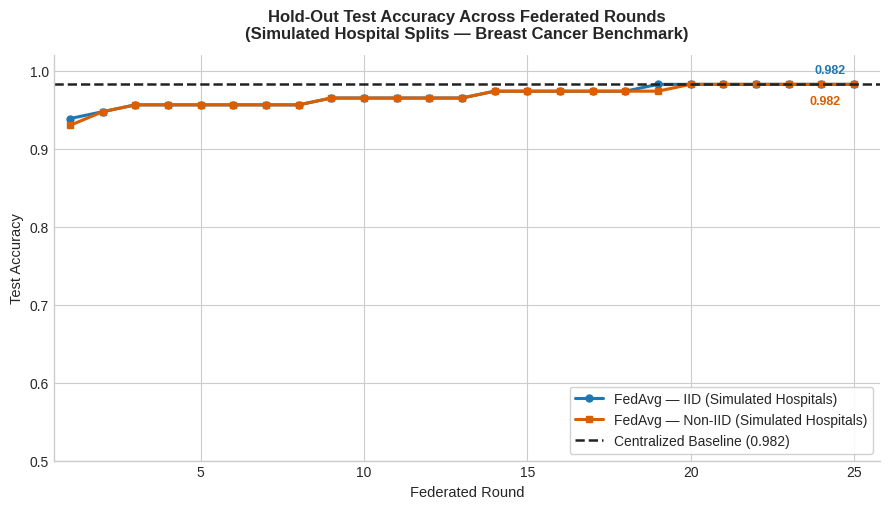

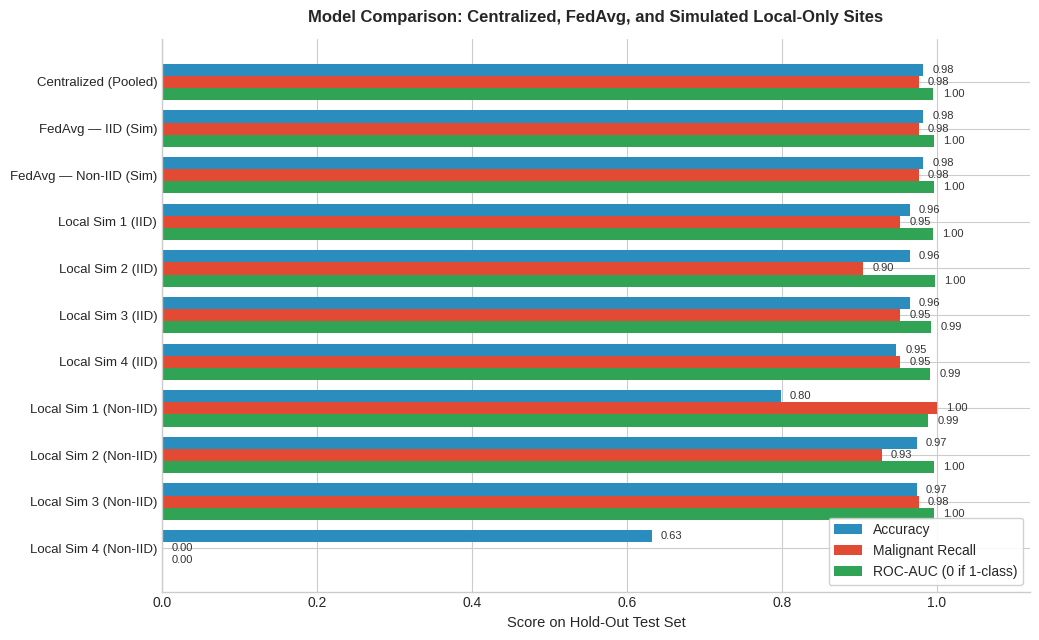

In [6]:
#Baselines, Evaluation, and Round-Accuracy Plot
iid_std, X_test_iid = federated_standardize(iid_clients, X_test)
non_iid_std, X_test_non_iid = federated_standardize(non_iid_clients, X_test)

# 1. Centralized baseline on pooled training features
X_train_pool = np.vstack([xc for xc, _ in iid_std])
y_train_pool = np.concatenate([yc for _, yc in iid_std])

cent_clf = LogisticRegression(max_iter=1000, random_state=SEED)
cent_clf.fit(X_train_pool, y_train_pool)

cent_preds = cent_clf.predict(X_test_iid)
cent_probs_benign = cent_clf.predict_proba(X_test_iid)[:, 1]
cent_metrics = {
    "model": "Centralized (Pooled)",
    "accuracy": accuracy_score(y_test, cent_preds),
    "recall_malignant": recall_score(y_test, cent_preds, pos_label=MALIGNANT_LABEL),
    "roc_auc": roc_auc_score(y_test, cent_probs_benign),
}

# 2. Local-only baselines for each simulated hospital (IID and Non-IID)
local_rows = []
for split_label, std_group, x_te in [
    ("IID", iid_std, X_test_iid),
    ("Non-IID", non_iid_std, X_test_non_iid),
]:
    for i, (xc, yc) in enumerate(std_group):
        unique_classes = np.unique(yc)
        if len(unique_classes) < 2:
            # Edge case: simulated non-IID site has only one class in local training data
            only_cls = unique_classes[0]
            preds = np.full(len(x_te), only_cls)
            auc_val = np.nan
        else:
            clf = LogisticRegression(max_iter=1000, random_state=SEED)
            clf.fit(xc, yc)
            preds = clf.predict(x_te)
            probs_benign = clf.predict_proba(x_te)[:, 1]
            auc_val = roc_auc_score(y_test, probs_benign)

        local_rows.append({
            "model": f"Local Sim {i+1} ({split_label})",
            "accuracy": accuracy_score(y_test, preds),
            "recall_malignant": recall_score(y_test, preds, pos_label=MALIGNANT_LABEL),
            "roc_auc": auc_val,
        })

# 3. Federated Averaging (25 rounds, 5 local epochs)
fed_iid = run_fedavg(iid_std, X_test_iid, y_test, rounds=25, local_epochs=5, lr=0.15)
fed_non_iid = run_fedavg(non_iid_std, X_test_non_iid, y_test, rounds=25, local_epochs=5, lr=0.15)

all_rows = [
    cent_metrics,
    {
        "model": "FedAvg — IID (Sim)",
        "accuracy": fed_iid["accuracy"],
        "recall_malignant": fed_iid["recall_malignant"],
        "roc_auc": fed_iid["roc_auc"],
    },
    {
        "model": "FedAvg — Non-IID (Sim)",
        "accuracy": fed_non_iid["accuracy"],
        "recall_malignant": fed_non_iid["recall_malignant"],
        "roc_auc": fed_non_iid["roc_auc"],
    },
] + local_rows

print(f"{'Model':<44} {'Accuracy':>10} {'Mal Recall':>12} {'ROC-AUC':>12}")
print("-" * 82)
for r in all_rows:
    auc_str = f"{r['roc_auc']:>12.4f}" if np.isfinite(r["roc_auc"]) else f"{'N/A (1-cls)':>12}"
    print(
        f"{r['model']:<44} {r['accuracy']:>10.4f} "
        f"{r['recall_malignant']:>12.4f} {auc_str}"
    )

# --- Plot 1: Styled Test Accuracy vs. Federated Round ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 5.2))

rounds_axis = np.arange(1, len(fed_iid["round_accs"]) + 1)
iid_line, = ax.plot(
    rounds_axis, fed_iid["round_accs"],
    marker="o", markersize=5, linewidth=2.2, color="#1f77b4",
    label="FedAvg — IID (Simulated Hospitals)"
)
noniid_line, = ax.plot(
    rounds_axis, fed_non_iid["round_accs"],
    marker="s", markersize=5, linewidth=2.2, color="#d95f02",
    label="FedAvg — Non-IID (Simulated Hospitals)"
)
cent_line = ax.axhline(
    cent_metrics["accuracy"], linestyle="--", linewidth=1.8, color="#222222",
    label=f"Centralized Baseline ({cent_metrics['accuracy']:.3f})"
)

# Subtle shaded area between IID and Non-IID curves
ax.fill_between(
    rounds_axis, fed_non_iid["round_accs"], fed_iid["round_accs"],
    color="#d95f02", alpha=0.08
)

# Annotate final round values
ax.annotate(
    f"{fed_iid['round_accs'][-1]:.3f}",
    xy=(rounds_axis[-1], fed_iid["round_accs"][-1]),
    xytext=(-28, 8), textcoords="offset points",
    fontsize=9, fontweight="bold", color="#1f77b4"
)
ax.annotate(
    f"{fed_non_iid['round_accs'][-1]:.3f}",
    xy=(rounds_axis[-1], fed_non_iid["round_accs"][-1]),
    xytext=(-32, -14), textcoords="offset points",
    fontsize=9, fontweight="bold", color="#d95f02"
)

ax.set_title(
    "Hold-Out Test Accuracy Across Federated Rounds\n(Simulated Hospital Splits — Breast Cancer Benchmark)",
    fontsize=12, fontweight="bold", pad=12
)
ax.set_xlabel("Federated Round", fontsize=10.5)
ax.set_ylabel("Test Accuracy", fontsize=10.5)
ax.set_xlim(0.5, len(rounds_axis) + 0.8)
ax.set_ylim(0.50, 1.02)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)

fig.tight_layout()
fig.savefig("figures/iid_vs_noniid_round_accuracy.png", dpi=200)
plt.show()

# --- Plot 2: Multi-Metric Comparison Across Models & Simulated Sites ---
labels = [r["model"] for r in all_rows]
acc_vals = [r["accuracy"] for r in all_rows]
rec_vals = [r["recall_malignant"] for r in all_rows]
auc_vals = [r["roc_auc"] if np.isfinite(r["roc_auc"]) else 0.0 for r in all_rows]

y_pos = np.arange(len(labels))
bar_h = 0.26

fig, ax = plt.subplots(figsize=(10.5, 6.5))
b1 = ax.barh(y_pos - bar_h, acc_vals, height=bar_h, color="#2b8cbe", label="Accuracy")
b2 = ax.barh(y_pos,         rec_vals, height=bar_h, color="#e34a33", label="Malignant Recall")
b3 = ax.barh(y_pos + bar_h, auc_vals, height=bar_h, color="#31a354", label="ROC-AUC (0 if 1-class)")

for bars in (b1, b2, b3):
    for bar in bars:
        w = bar.get_width()
        ax.text(
            w + 0.012, bar.get_y() + bar.get_height() / 2,
            f"{w:.2f}", va="center", ha="left", fontsize=8, color="#333333"
        )

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9.5)
ax.invert_yaxis()  # Top-to-bottom order matching table
ax.set_xlim(0, 1.12)
ax.set_xlabel("Score on Hold-Out Test Set", fontsize=10.5)
ax.set_title(
    "Model Comparison: Centralized, FedAvg, and Simulated Local-Only Sites",
    fontsize=12, fontweight="bold", pad=12
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)

fig.tight_layout()
fig.savefig("figures/model_comparison_metrics.png", dpi=200)
plt.show()

sigma=0.00 -> Accuracy: 0.9825, Malignant Recall: 0.9762, ROC-AUC: 0.9960
sigma=0.02 -> Accuracy: 0.9737, Malignant Recall: 0.9762, ROC-AUC: 0.9957
sigma=0.05 -> Accuracy: 0.9474, Malignant Recall: 0.9762, ROC-AUC: 0.9957
sigma=0.10 -> Accuracy: 0.9474, Malignant Recall: 0.9762, ROC-AUC: 0.9937
sigma=0.20 -> Accuracy: 0.9298, Malignant Recall: 0.9762, ROC-AUC: 0.9907
sigma=0.35 -> Accuracy: 0.9298, Malignant Recall: 0.9762, ROC-AUC: 0.9871


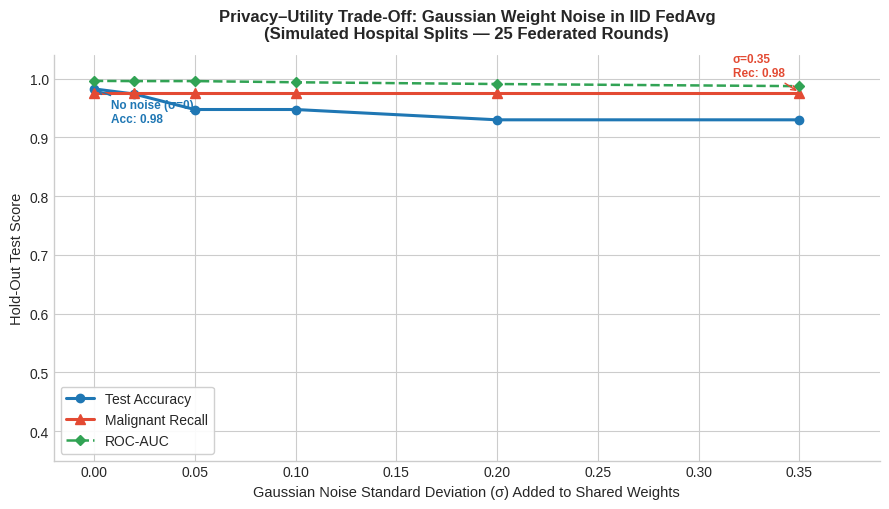

In [8]:
#Gaussian Weight Noise Experiment
plt.style.use("seaborn-v0_8-whitegrid")

noise_levels = [0.0, 0.02, 0.05, 0.10, 0.20, 0.35]
noisy_accs = []
noisy_recalls = []
noisy_aucs = []

for sigma in noise_levels:
    res = run_fedavg(
        iid_std, X_test_iid, y_test, rounds=25, local_epochs=5, lr=0.15, noise_std=sigma
    )
    noisy_accs.append(res["accuracy"])
    noisy_recalls.append(res["recall_malignant"])
    noisy_aucs.append(res["roc_auc"])
    print(
        f"sigma={sigma:>4.2f} -> Accuracy: {res['accuracy']:.4f}, "
        f"Malignant Recall: {res['recall_malignant']:.4f}, ROC-AUC: {res['roc_auc']:.4f}"
    )

fig, ax = plt.subplots(figsize=(9, 5.2))

ax.plot(
    noise_levels, noisy_accs,
    marker="o", markersize=6, linewidth=2.2, color="#1f77b4",
    label="Test Accuracy"
)
ax.plot(
    noise_levels, noisy_recalls,
    marker="^", markersize=6.5, linewidth=2.2, color="#e34a33",
    label="Malignant Recall"
)
ax.plot(
    noise_levels, noisy_aucs,
    marker="D", markersize=5, linewidth=1.8, linestyle="--", color="#31a354",
    label="ROC-AUC"
)

# Highlight baseline (no noise) and highest noise points
ax.annotate(
    f"No noise (σ=0)\nAcc: {noisy_accs[0]:.2f}",
    xy=(noise_levels[0], noisy_accs[0]),
    xytext=(12, -24), textcoords="offset points",
    fontsize=8.5, fontweight="bold", color="#1f77b4",
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.0)
)
ax.annotate(
    f"σ={noise_levels[-1]}\nRec: {noisy_recalls[-1]:.2f}",
    xy=(noise_levels[-1], noisy_recalls[-1]),
    xytext=(-48, 12), textcoords="offset points",
    fontsize=8.5, fontweight="bold", color="#e34a33",
    arrowprops=dict(arrowstyle="->", color="#e34a33", lw=1.0)
)

ax.set_title(
    "Privacy–Utility Trade-Off: Gaussian Weight Noise in IID FedAvg\n(Simulated Hospital Splits — 25 Federated Rounds)",
    fontsize=12, fontweight="bold", pad=12
)
ax.set_xlabel("Gaussian Noise Standard Deviation (σ) Added to Shared Weights", fontsize=10.5)
ax.set_ylabel("Hold-Out Test Score", fontsize=10.5)
ax.set_xlim(-0.02, max(noise_levels) + 0.04)
ax.set_ylim(0.35, 1.04)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.92)

fig.tight_layout()
fig.savefig("figures/dp_noise_tradeoff.png", dpi=200)
plt.show()

In [9]:
%%writefile README.md
# Simulated Hospital Federated Learning Prototype (Breast Cancer Benchmark)

> **Important Data Disclaimer:** All hospital sites (`Hospital_Sim_1` – `Hospital_Sim_4`) in this project are **simulated** by splitting the public `sklearn.datasets.load_breast_cancer()` benchmark dataset. **No real patient or clinical hospital records are used**, and this prototype is for educational and portfolio demonstration only—not clinical diagnosis.

## Problem & Goal

Healthcare organizations often cannot pool raw patient records centrally due to privacy regulations, institutional governance, and data-sharing barriers. The goal of this prototype is to implement **Federated Averaging (FedAvg)** from scratch in `numpy` across **4 simulated hospital sites** without sharing raw patient rows, and compare its performance against:

1. **Centralized training** (logistic regression on pooled training data).
2. **Local-only training** (each simulated site training independently on its own split).

We evaluate both **IID** (unequal random splits) and **Non-IID** (unequal splits with skewed malignant/benign class balance) partitions on a held-out **20% stratified test set**.

## Method

* **Train / Test Split (`SEED = 42`):** Stratified 80/20 split of `sklearn.datasets.load_breast_cancer()` (`569` samples, `30` numeric features), keeping the 20% test set strictly untouched during training. In scikit-learn's dataset, `target == 0` is **malignant** and `target == 1` is **benign**.
* **Simulated Hospital Partitions (4 Sites):**
  * **IID Split:** Random permutation of the training set divided into unequal site sizes (`35%`, `25%`, `25%`, `15%`).
  * **Non-IID Split:** Unequal site sizes with skewed malignant/benign ratios across sites (e.g., heavily malignant vs. heavily benign splits), including edge cases where a single-class local split can occur.
* **Privacy-Aware Standardization:** Instead of fitting a scaler on pooled raw patient records, global mean and standard deviation are computed from per-site sample counts, feature sums, and sums of squared deviations around the global mean (summary moments only).
* **Hand-Written FedAvg (`numpy`):** Over `25` communication rounds (`5` local gradient-descent epochs per round, L2 regularization, learning rate `0.15`), each simulated hospital trains a binary logistic regression model starting from the current global weights `(w, b)`. The server aggregates model parameters weighted by each site's sample count.
* **Optional Gaussian Weight Noise Experiment:** Zero-mean Gaussian noise ($\mathcal{N}(0, \sigma^2)$) is added to aggregated weights across varying noise levels ($\sigma$) to illustrate the trade-off between weight perturbation and predictive utility.

## Results

*(Replace the bracketed values below with the exact metrics printed by your notebook run.)*

| Model / Setup | Data Split | Test Accuracy | Malignant Recall | ROC-AUC |
| :--- | :--- | :---: | :---: | :---: |
| Centralized Logistic Regression | Pooled Train | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| FedAvg (25 rounds, 5 local epochs) | IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| FedAvg (25 rounds, 5 local epochs) | Non-IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_1` | IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_2` | IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_3` | IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_4` | IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_1` | Non-IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_2` | Non-IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_3` | Non-IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |
| Local-Only — `Hospital_Sim_4` | Non-IID (Simulated) | `[paste acc]` | `[paste recall]` | `[paste auc]` |

### Generated Figures

* `figures/iid_vs_noniid_round_accuracy.png` — Hold-out test accuracy across federated rounds for IID vs. Non-IID simulated hospitals compared to the centralized baseline.
* `figures/model_comparison_metrics.png` — Comparison of Accuracy, Malignant Recall, and ROC-AUC across centralized, federated, and local-only simulated sites.
* `figures/dp_noise_tradeoff.png` — Effect of adding Gaussian noise ($\sigma$) to shared weights on test accuracy, malignant recall, and ROC-AUC.

## Key Takeaways & Remaining Privacy Risks

* **When FedAvg matches centralized training:** Under IID partitions with a convex/smooth model like logistic regression and well-chosen learning rate and local epoch count, FedAvg closely tracks centralized performance.
* **What is lost under Non-IID data:** Skewed class distributions cause local updates to drift in conflicting directions ("client drift"), which can slow convergence, reduce overall accuracy, or hurt recall on the malignant class—where missed malignant cases (false negatives) are critical.
* **Privacy risks that remain:** Sharing model parameters or summary statistics instead of raw patient tables **does not guarantee privacy**. Updates can still leak sensitive information via gradient/model inversion, membership inference, or class-distribution cues. Plain FedAvg lacks formal differential privacy guarantees or secure aggregation unless combined with gradient clipping, calibrated noise (e.g., DP-SGD), and cryptographic aggregation.

## Limitations

* **Simulated dataset & partitions:** The 4 hospitals are synthetic splits of a single public dataset (`569` rows total), not real multi-center clinical cohorts with domain shift, missingness, or varying EHR schemas.
* **Simple linear model:** Logistic regression is fast and transparent for a prototype, but non-linear clinical models (e.g., neural networks or gradient-boosted trees) behave differently under non-IID skew.
* **Heuristic noise vs. formal DP:** Adding Gaussian noise to aggregated weights demonstrates a qualitative privacy–utility trade-off, not a formal $(\varepsilon, \delta)$-differential privacy bound.

## How to Run

1. Open `federated_breast_cancer.ipynb` in Jupyter Notebook or Google Colab.
2. Run all cells in order (`Shift + Enter`).
3. Inspect the printed metrics and generated plots in `figures/`.

Writing README.md


In [10]:
%%writefile requirements.txt
numpy>=1.26.0
scikit-learn>=1.4.0
matplotlib>=3.8.0
jupyter>=1.0.0

Writing requirements.txt


In [11]:
!zip -r project_bundle.zip README.md requirements.txt figures
from google.colab import files
files.download("project_bundle.zip")

  adding: README.md (deflated 60%)
  adding: requirements.txt (deflated 9%)
  adding: figures/ (stored 0%)
  adding: figures/iid_vs_noniid_round_accuracy.png (deflated 16%)
  adding: figures/dp_noise_tradeoff.png (deflated 14%)
  adding: figures/model_comparison_metrics.png (deflated 23%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>